--- Naive Bayes Classification Results ---
Accuracy: 0.3177
Precision: 0.3351
Recall   : 0.3177
F1 Score : 0.2856

Classification Report:
              precision    recall  f1-score   support

         cel       0.60      0.09      0.16        95
         cla       0.24      0.56      0.34        96
         flu       0.30      0.08      0.13        85
         gac       0.41      0.30      0.34       151
         gel       0.36      0.19      0.25       139
         org       0.43      0.41      0.42       145
         pia       0.34      0.58      0.43       142
         sax       0.00      0.00      0.00       114
         tru       0.36      0.22      0.27       119
         vio       0.37      0.22      0.28       109
         voi       0.25      0.64      0.36       146

    accuracy                           0.32      1341
   macro avg       0.33      0.30      0.27      1341
weighted avg       0.34      0.32      0.29      1341



<Figure size 1000x800 with 0 Axes>

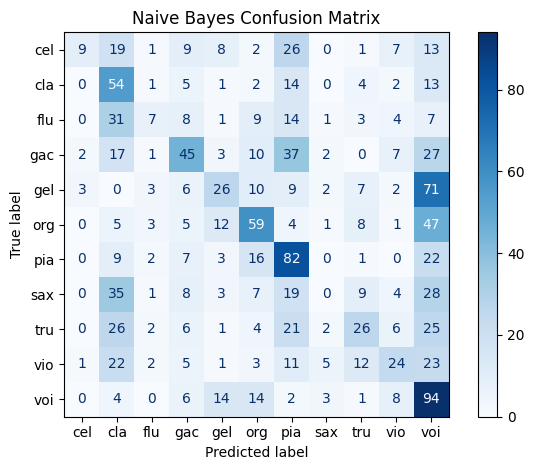

In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# 1. Load the dataset
data = pd.read_csv(r"C:\Users\LENOVO\Documents\ML Project(Instrument Classifier)\Music Dataset.csv")
X = data.drop("Instrument", axis=1)
y = data["Instrument"]

# 2. Split the data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 3. Train the Naive Bayes model
model = GaussianNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# 4. Print evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")
conf_matrix = confusion_matrix(y_test, y_pred)

print("--- Naive Bayes Classification Results ---")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 5. Display confusion matrix
plt.figure(figsize=(10, 8))
ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=model.classes_).plot(cmap='Blues')
plt.title('Naive Bayes Confusion Matrix')
plt.tight_layout()
plt.show()